# Problem 3 — Final figures

Error comparisons, matched runtime distributions, and summary tables from saved results.

In [7]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if (ROOT / 'problem-3-global-pgm').is_dir():
    ROOT = ROOT / 'problem-3-global-pgm'
if not (ROOT / 'src/pgm.py').exists():
    raise RuntimeError('Open this notebook from the repository root or Problem 3 directory.')
loaded = sys.modules.get('src')
if loaded and Path(loaded.__file__).resolve().parent != ROOT / 'src':
    raise RuntimeError('Restart the kernel: another project has imported the src package.')
sys.path.insert(0, str(ROOT))
import importlib
from src import search as _search, probes as _probes
importlib.reload(_search)
importlib.reload(_probes)
from src.reporting import final_figures as _final_figures
_final_figures = importlib.reload(_final_figures)
load_saved_runs = _final_figures.load_saved_runs

OUTPUT = ROOT / 'results/final_figures'

font_manager.findfont(font_manager.FontProperties(family='Times New Roman'),
                      fallback_to_default=False)


FontPath('/System/Library/Fonts/Supplemental/Times New Roman.ttf', 0)

In [8]:
DATASETS, PROVENANCE = load_saved_runs(ROOT)
for study, info in PROVENANCE.items():
    print(f"{study.title()}: {info['case_budgets']:,} complete instance/budget groups")

Compact: 10,755 complete instance/budget groups
Extended: 17,247 complete instance/budget groups


In [9]:
# Reload plotting changes even when this cell is rerun on its own.
import importlib
from src.reporting import final_figures as _final_figures
_final_figures = importlib.reload(_final_figures)
FIGURES, RUNTIME_TABLE, MAXIMUM_GAP_TABLE = _final_figures.create_outputs(DATASETS, OUTPUT)
PROVENANCE['report'] = {
    'weighting': 'equal instances; average unique budgets and states within instance',
    'input_state_allocation': 'VND for compact and extended',
    'allocation_reference': {'compact': 'Exhaustive', 'extended': 'Greedy'},
    'maximum_gap': 'maximum signed error difference over matched cases and budgets',
    'runtime': 'standalone allocation + final PGM; Exhaustive uses search time',
    'runtime_ecdf': 'matched case, budget, and input state; separate study and dimension',
    'bar_confidence': 0.95,
    'bootstrap_seed': 20261014,
    'bootstrap_resamples': 2000,
    'bootstrap': 'percentile; field-instance clusters stratified by K, M, and field family',
}
(OUTPUT / 'provenance.json').write_text(json.dumps(PROVENANCE, indent=2) + '\n')


3038

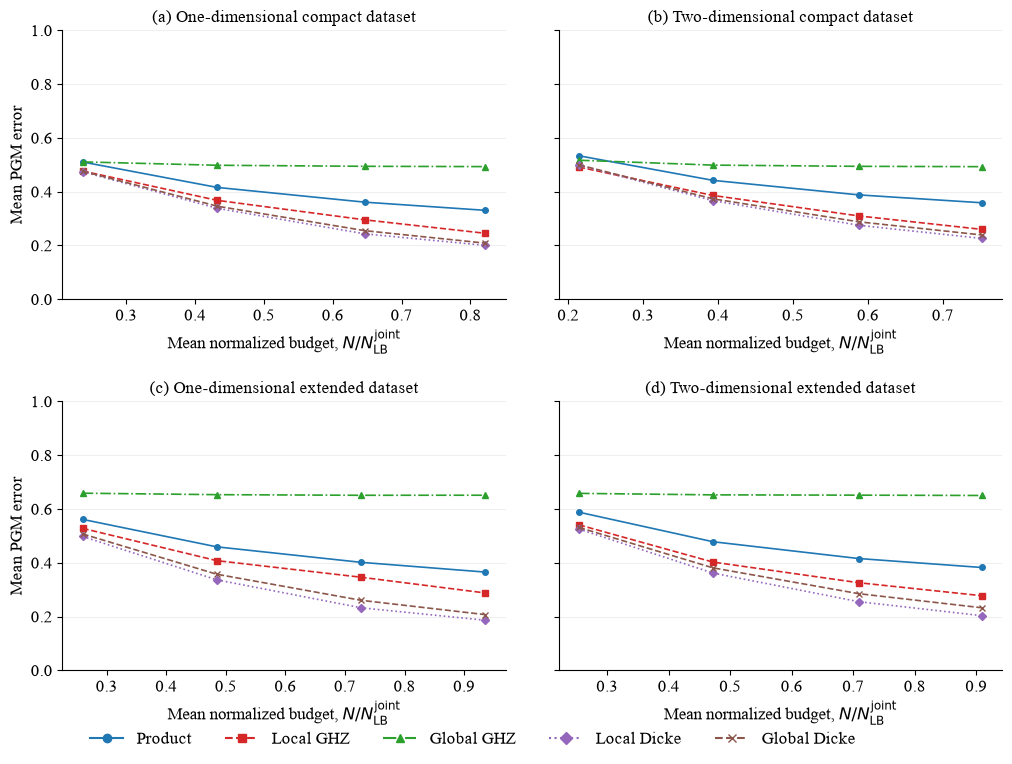

**Figure 16.** Mean PGM error for five input states using VND allocations on compact and extended datasets.

In [10]:
display(FIGURES[0])
plt.close(FIGURES[0])
display(Markdown('**Figure 16.** Mean PGM error for five input states using VND allocations on compact and extended datasets.'))


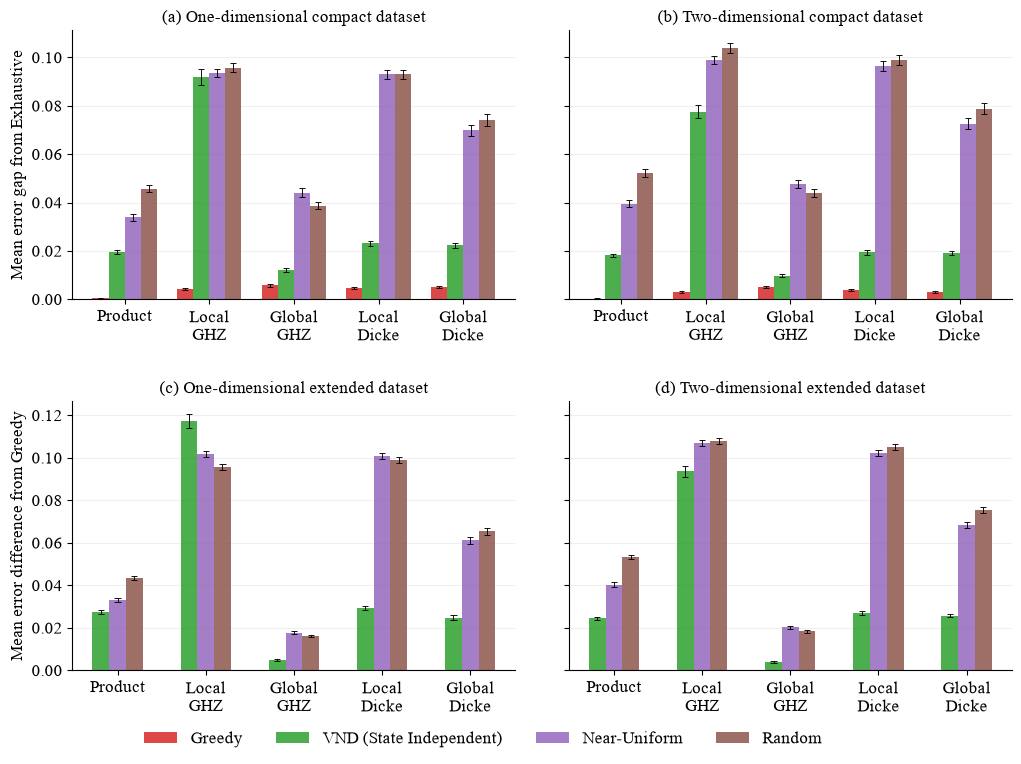

**Figure 17.** Allocation error differences from Exhaustive (compact) or Greedy (extended). Negative values indicate lower error than the reference. Error bars show 95% bootstrap confidence intervals.

In [11]:
display(FIGURES[1])
plt.close(FIGURES[1])
display(Markdown('**Figure 17.** Allocation error differences from Exhaustive (compact) or Greedy (extended). Negative values indicate lower error than the reference. Error bars show 95% bootstrap confidence intervals.'))

In [12]:
display(Markdown(RUNTIME_TABLE))
display(Markdown('**Table 1.** Mean runtime on Compact datasets for Exhaustive, Greedy, and VND, averaged over input states and budgets.'))


| Dimension | Method | Mean runtime (ms) |
|---|---|---:|
| 1D | Exhaustive | 69.758 |
| 1D | Greedy | 3.493 |
| 1D | VND (State Independent) | 0.366 |
| 2D | Exhaustive | 79.094 |
| 2D | Greedy | 3.628 |
| 2D | VND (State Independent) | 0.374 |

**Table 1.** Mean runtime on Compact datasets for Exhaustive, Greedy, and VND, averaged over input states and budgets.

In [13]:
display(Markdown(MAXIMUM_GAP_TABLE))
display(Markdown('**Maximum error gaps.** Largest signed difference across cases and budgets, separately for each dataset and input state. References: Exhaustive (compact), Greedy (extended).'))

| dataset | input_state | reference | Greedy | VND (State Independent) | Near-Uniform | Random |
| --- | --- | --- | --- | --- | --- | --- |
| Compact 1D | Product | Exhaustive | 0.044201954 | 0.19691938 | 0.34882018 | 0.50752702 |
| Compact 1D | Local GHZ | Exhaustive | 0.10957932 | 0.54975682 | 0.35515549 | 0.53505598 |
| Compact 1D | Global GHZ | Exhaustive | 0.25993735 | 0.32796806 | 0.31759536 | 0.32242377 |
| Compact 1D | Local Dicke | Exhaustive | 0.15183477 | 0.22164407 | 0.34882018 | 0.50628109 |
| Compact 1D | Global Dicke | Exhaustive | 0.15620077 | 0.28307536 | 0.35639218 | 0.486456 |
| Compact 2D | Product | Exhaustive | 0.075990772 | 0.20053833 | 0.29298082 | 0.43150378 |
| Compact 2D | Local GHZ | Exhaustive | 0.18235 | 0.53162565 | 0.36218841 | 0.50384952 |
| Compact 2D | Global GHZ | Exhaustive | 0.17207444 | 0.2600397 | 0.32443922 | 0.33075155 |
| Compact 2D | Local Dicke | Exhaustive | 0.14107209 | 0.1847046 | 0.39027052 | 0.4565357 |
| Compact 2D | Global Dicke | Exhaustive | 0.16162979 | 0.22240397 | 0.37555042 | 0.42902563 |
| Extended 1D | Product | Greedy | 0 | 0.29610192 | 0.27479391 | 0.35855615 |
| Extended 1D | Local GHZ | Greedy | 0 | 0.74786959 | 0.43003598 | 0.5628858 |
| Extended 1D | Global GHZ | Greedy | 0 | 0.30007557 | 0.32119703 | 0.32119703 |
| Extended 1D | Local Dicke | Greedy | 0 | 0.27704915 | 0.47563531 | 0.47598835 |
| Extended 1D | Global Dicke | Greedy | 0 | 0.24871797 | 0.42634479 | 0.41466789 |
| Extended 2D | Product | Greedy | 0 | 0.32220249 | 0.41909769 | 0.4273232 |
| Extended 2D | Local GHZ | Greedy | 0 | 0.66455102 | 0.4902365 | 0.51740908 |
| Extended 2D | Global GHZ | Greedy | 0 | 0.27928528 | 0.31698103 | 0.32777266 |
| Extended 2D | Local Dicke | Greedy | 0 | 0.27639424 | 0.41909769 | 0.44341973 |
| Extended 2D | Global Dicke | Greedy | 0 | 0.24640567 | 0.43118387 | 0.42815651 |

**Maximum error gaps.** Largest signed difference across cases and budgets, separately for each dataset and input state. References: Exhaustive (compact), Greedy (extended).

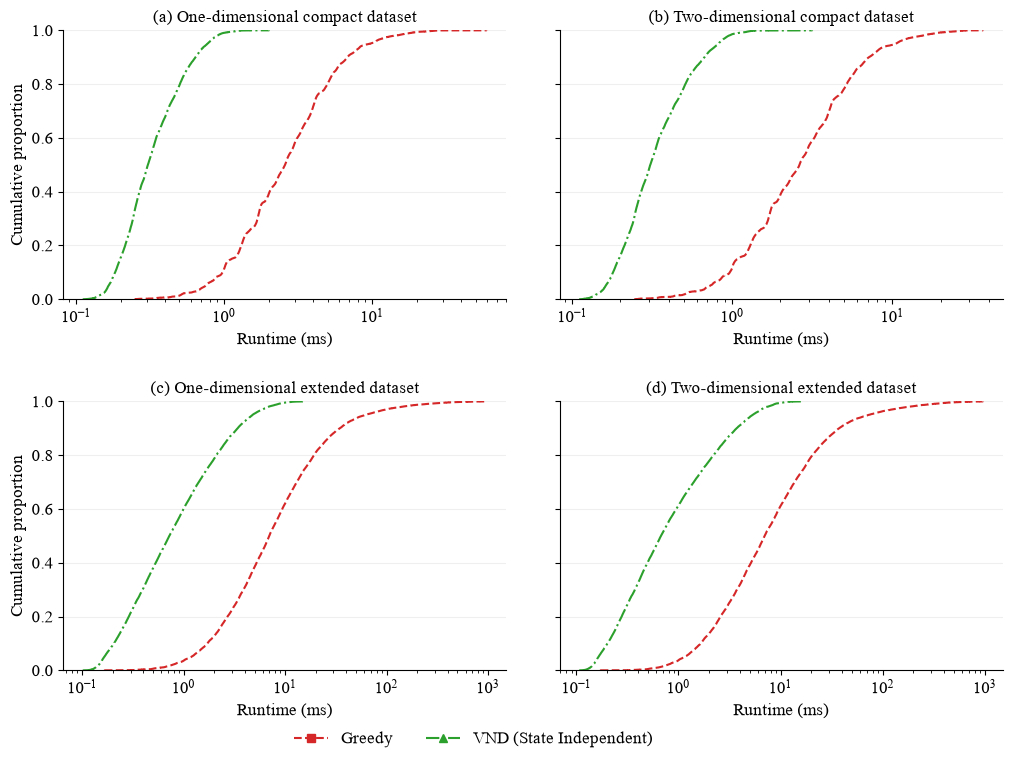

**Runtime ECDF.** Greedy and VND on matched cases, budgets, and input states. Runtime includes allocation and final PGM evaluation; the horizontal axis is logarithmic.

In [14]:
display(FIGURES[2])
plt.close(FIGURES[2])
display(Markdown('**Runtime ECDF.** Greedy and VND on matched cases, budgets, and input states. Runtime includes allocation and final PGM evaluation; the horizontal axis is logarithmic.'))